# آزمون فرضیه دوم: نسبت سابقه به سن بازیکن های تیم قهرمان

اینجا می خوایم فرضیه دوم توضیح پروژه رو بررسی کنیم: آیا میانگین نسبت سابقه به سن بازیکن های فعال تیم های قهرمان، توی دو فصل اخیر بیشتر از دو فصل قبلش شده؟

توی صورت پروژه به این نسبت «توانایی ذاتی» گفته شده. ما هم برای انجام این بخش از این تعریف استفاده می کنیم، ولی خود نسبت قرار نیست استعداد یا توانایی واقعی بازیکن رو اندازه بگیره. مثلا کسی که زودتر وارد لیگ شده ممکنه نسبت بالاتری داشته باشه، بدون اینکه بشه فقط از همین عدد درباره استعدادش قضاوت کرد.

## کدوم فصل ها و بازیکن ها رو بررسی می کنیم؟

دوره قبلی شامل فصل های ۲۰۲۳ و ۲۰۲۴ و دوره اخیر شامل ۲۰۲۵ و ۲۰۲۶ می‌شه. سال ها همون سال پایان فصل هستن و قهرمان هر فصل از دیتابیس پروژه مشخص می شه.

فقط بازیکن هایی وارد نمونه می شن که توی همون فصل حداقل یک بازی در فصل عادی برای تیم قهرمان داشتن. ردیف مجموع بازیکن های چندتیمی هم حذف می شه تا بازی برای تیم های دیگه حساب نشه.

تحلیل مستقیما از دیتابیس `DB/basketbal_da.db` انجام می شه؛ سایت دوباره خونده نمی شه و اتصال فقط خواندنیه، پس نوت بوک دیتابیس رو تغییر نمی ده. کامل بودن داده ها، به خصوص فصل ۲۰۲۶، باید جدا بررسی بشه.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

project_root = Path.cwd()
if not (project_root / "DB" / "basketbal_da.db").is_file():
    project_root = project_root.parent

database_path = (project_root / "DB" / "basketbal_da.db").resolve()
with sqlite3.connect(f"{database_path.as_uri()}?mode=ro", uri=True) as connection:
    champions = pd.read_sql_query(
        """
        SELECT s.season, c.team_id, c.team_name
        FROM champions AS c
        JOIN seasons AS s ON s.season_id = c.season_id
        """,
        connection,
    )
    rosters = pd.read_sql_query(
        """
        SELECT s.season, e.team_id, e.player_id, e.experience_years
        FROM experience AS e
        JOIN seasons AS s ON s.season_id = e.season_id
        """,
        connection,
    )
    player_seasons = pd.read_sql_query(
        """
        SELECT s.season, p.team_id, p.player_id, p.age, p.games, p.is_total
        FROM player_season AS p
        JOIN seasons AS s ON s.season_id = p.season_id
        """,
        connection,
    )

previous_seasons = [2023, 2024]
recent_seasons = [2025, 2026]
selected_seasons = previous_seasons + recent_seasons
alpha = 0.05

selected_champions = champions.loc[
    champions["season"].isin(selected_seasons),
    ["season", "team_id", "team_name"],
].copy()
assert set(selected_champions["season"]) == set(selected_seasons)
assert not selected_champions["season"].duplicated().any()
selected_champions

,season,team_id,team_name
3,2023,11,Denver Nuggets
4,2024,5,Boston Celtics
5,2025,24,Oklahoma City Thunder
6,2026,23,New York Knicks


## چرا این جدول ها رو این جوری وصل می کنیم؟

از SQLite پروژه با `sqlite3` خود پایتون می خونیم تا از رابطه های موجود استفاده کنیم. اتصال فقط خواندنیه؛ نه داده ها تغییر می کنن، نه مسیر اشتباه باعث ساخت دیتابیس خالی می شه.

`champions` تیم قهرمان، `player_season` سن و بازی ها و `experience` سابقه رو مشخص می کنن. با `seasons` شناسه داخلی فصل رو به سال پایانش تبدیل می کنیم؛ شناسه تیم هم بین جدول ها مشترکه و به `team` برمی گرده. داده ها رو با SELECT می خونیم و برای روشن موندن مرحله های انتخاب نمونه، اتصال و فیلتر رو توی pandas انجام می دیم.

کلید اتصال `season`، `team_id` و `player_id` است؛ شناسه بازیکن به تنهایی کافی نیست چون فصل و تیمش می تونه عوض بشه. سن مربوط به همون فصله و سابقه تعداد فصل های قبلی NBA/ABA؛ پس صفر برای تازه واردها درسته، حتی اگر توی فصل جاری بازی کرده باشن.

بعد از انتخاب بازیکن های فعال تیم قهرمان، سابقه رو با اتصال چپ اضافه می کنیم تا سابقه ناموجود باعث حذف پنهانی بازیکن نشه. موارد خالی گزارش می شن و اعتبارسنجی اتصال، جلوی چند برابر شدن ردیف ها رو می گیره؛ رکورد متناقض هم اجرا رو متوقف می کنه.

In [2]:
keys = ["season", "team_id", "player_id"]
active_stats = player_seasons.loc[
    player_seasons["season"].isin(selected_seasons)
    & player_seasons["is_total"].eq(0)
    & player_seasons["games"].gt(0),
    keys + ["age", "games"],
].copy()
assert not active_stats.duplicated(keys).any()

active_champions = active_stats.merge(
    selected_champions,
    on=["season", "team_id"],
    how="inner",
    validate="many_to_one",
)
experience = rosters.loc[
    rosters["season"].isin(selected_seasons),
    keys + ["experience_years"],
].drop_duplicates()

observations = active_champions.merge(
    experience,
    on=keys,
    how="left",
    validate="one_to_one",
    indicator=True,
)
assert len(observations) == len(active_champions)
observations.groupby(["season", "team_name"]).size().rename("active_players").to_frame()

,,active_players
season,team_name,
2023,Denver Nuggets,18
2024,Boston Celtics,19
2025,Oklahoma City Thunder,19
2026,New York Knicks,20


## با مقدار خالی و سابقه صفر چیکار می کنیم؟

سن یا سابقه خالی رو گزارش و قبل از محاسبه نسبت حذف می کنیم، ولی صفر واقعی می مونه؛ «نامعلوم» با «تازه وارد» فرق داره. جایگذاری با صفر یا میانگین می تونه نتیجه و پراکندگی رو عوض کنه. حذف مقدارهای خالی هم ممکنه نمونه رو جهت دار کنه، پس اگر زیاد باشن باید علتشون بررسی بشه.

سن باید مثبت و سابقه نامنفی باشه؛ مقدار نامعتبر اجرا رو متوقف می کنه.

In [3]:
quality = pd.Series(
    {
        "active_player_seasons": len(observations),
        "missing_roster_match": observations["_merge"].eq("left_only").sum(),
        "missing_age": observations["age"].isna().sum(),
        "missing_experience": observations["experience_years"].isna().sum(),
        "excluded_missing_rows": observations[["age", "experience_years"]].isna().any(axis=1).sum(),
        "rookie_player_seasons": observations["experience_years"].eq(0).sum(),
    },
    name="count",
)
display(quality.to_frame())

assert observations["age"].dropna().gt(0).all()
assert observations["experience_years"].dropna().ge(0).all()

valid = observations.dropna(subset=["age", "experience_years"]).copy()
valid["experience_age_ratio"] = valid["experience_years"] / valid["age"]
valid["period"] = "Previous (2023-2024)"
valid.loc[valid["season"].isin(recent_seasons), "period"] = "Recent (2025-2026)"
assert valid["experience_age_ratio"].between(0, 1, inclusive="left").all()
assert valid.loc[valid["experience_years"].eq(0), "experience_age_ratio"].eq(0).all()

,count
active_player_seasons,76
missing_roster_match,0
missing_age,0
missing_experience,0
excluded_missing_rows,0
rookie_player_seasons,12


## چرا هر بازیکن توی هر دوره فقط یک بار حساب می شه؟

اگر بازیکن توی دو فصل یک دوره حضور داشته باشه، میانگین نسبت های دو فصلش رو می گیریم تا دو برابر بقیه وزن نگیره. این «میانگین نسبت ها» است، نه «نسبت میانگین سابقه به میانگین سن».

گرفتن هر بازیکن-فصل به عنوان یک مشاهده، هم وزن فرد تکراری رو بیشتر می کنه، هم استقلال رو ضعیف تر. انتخاب تیم-فصل وابستگی هم تیمی ها رو بهتر لحاظ می کنه، ولی فقط دو مشاهده در هر دوره می ده. روش فعلی وزن افراد رو برابر می کنه، هرچند وابستگی هم تیمی ها باقی می مونه.

اگر بازیکنی بین دو دوره مشترک باشه، اجرا متوقف می شه تا فرض استقلال دوباره بررسی بشه. آزمون زوجی هم جایگزین خودکار نیست؛ نمونه های واقعا جفت شده می خواد.

In [4]:
period_order = ["Previous (2023-2024)", "Recent (2025-2026)"]
player_ratios = valid.groupby(["period", "player_id"], as_index=False).agg(
    experience_age_ratio=("experience_age_ratio", "mean"),
    seasons_observed=("season", "nunique"),
)
assert not player_ratios.duplicated(["period", "player_id"]).any()

previous = player_ratios.loc[
    player_ratios["period"].eq(period_order[0]), "experience_age_ratio"
]
recent = player_ratios.loc[
    player_ratios["period"].eq(period_order[1]), "experience_age_ratio"
]
previous_ids = set(player_ratios.loc[player_ratios["period"].eq(period_order[0]), "player_id"])
recent_ids = set(player_ratios.loc[player_ratios["period"].eq(period_order[1]), "player_id"])
shared_ids = previous_ids & recent_ids
print("Players shared between periods:", len(shared_ids))
assert not shared_ids
assert len(previous) > 1 and len(recent) > 1

summary = player_ratios.groupby("period")["experience_age_ratio"].agg(
    count="count", mean="mean", median="median", std="std"
).reindex(period_order)
display(summary)
display(player_ratios.loc[player_ratios["seasons_observed"].gt(1)])

Players shared between periods: 0


,count,mean,median,std
period,,,,
Previous (2023-2024),37,0.176384,0.153846,0.128869
Recent (2025-2026),38,0.128682,0.097619,0.103970


,period,player_id,experience_age_ratio,seasons_observed
58,Recent (2025-2026),jonesdi01,0.020833,2


## فرض ها و روش آزمون

فرض ها رو قبل از نتیجه مشخص می کنیم:

- `H₀: μ_recent ≤ μ_previous`
- `H₁: μ_recent > μ_previous`

سطح خطا `0.05` است. چون سوال درباره افزایشه، آزمون یک طرفه است و جهتش رو بعد از نتیجه عوض نمی کنیم. رد نشدن فرض صفر هم اثبات برابری یا کاهش نیست.

Welch رو با `equal_var=False` انتخاب می کنیم تا برخلاف Student، برابری واریانس ها لازم نباشه. نسبت بین صفر و یکه و صفر واقعی هم داره؛ نرمال بودنش تضمین نشده. گروه های حدود ۴۰ نفره و نمودارها به ارزیابی کمک می کنن، ولی اعتبار آزمون رو تضمین نمی کنن.

Shapiro–Wilk فقط برای بررسی توزیعه؛ p-value بزرگ، نرمال بودن رو ثابت نمی کنه و با نتیجه کوچکش هم روش از پیش انتخاب شده رو عوض نمی کنیم. Mann–Whitney مستقیما آزمون میانگین ها نیست. جایگشت و bootstrap هم فرض استقلال رو کنار نمی ذارن؛ برای حفظ سطح آموزشی و روش از پیش مشخص شده، اینجا ازشون استفاده نمی کنیم.

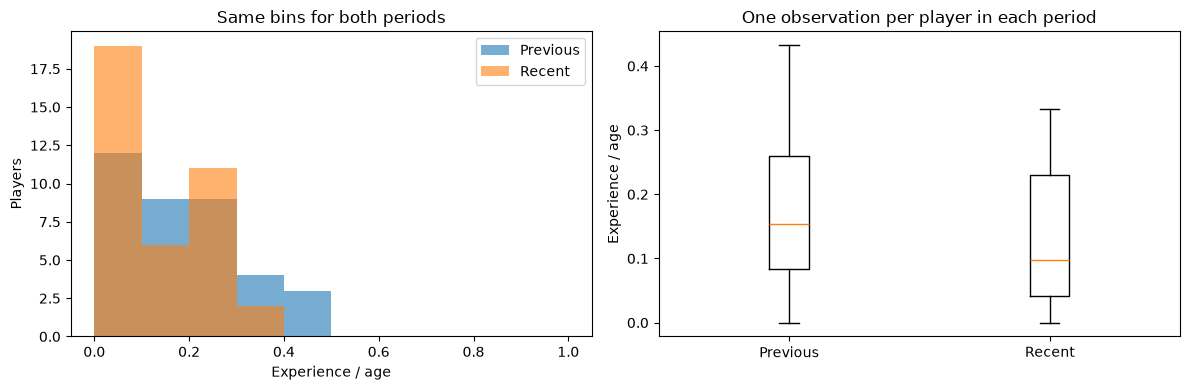

,W,p_value
period,,
Previous (2023-2024),0.940564,0.048071
Recent (2025-2026),0.915219,0.007055


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = [i / 10 for i in range(11)]
axes[0].hist(previous, bins=bins, alpha=0.6, label="Previous")
axes[0].hist(recent, bins=bins, alpha=0.6, label="Recent")
axes[0].set(xlabel="Experience / age", ylabel="Players", title="Same bins for both periods")
axes[0].legend()
axes[1].boxplot([previous, recent], tick_labels=["Previous", "Recent"])
axes[1].set(ylabel="Experience / age", title="One observation per player in each period")
plt.tight_layout()
plt.show()

normality = []
for period, values in zip(period_order, [previous, recent]):
    result = stats.shapiro(values)
    normality.append({"period": period, "W": result.statistic, "p_value": result.pvalue})
pd.DataFrame(normality).set_index("period")

## اجرای Welch و فاصله اطمینان

دوره اخیر رو اول می دیم تا اختلاف و آماره مربوط به «اخیر منهای قبلی» باشن. تصمیم با p-value یک طرفه گرفته می شه، ولی فاصله اطمینان رو طبق برنامه، دوطرفه و ۹۵ درصدی از همون Welch می گیریم؛ فاصله یک طرفه یک انتهای نامحدود داره.

فاصله اطمینان اندازه و عدم قطعیت اختلاف رو نشون می ده؛ p-value به تنهایی اهمیت عملی رو مشخص نمی کنه. عبور فاصله دوطرفه ۹۵ درصدی از صفر هم دقیقا معادل مرز تصمیم آزمون یک طرفه نیست.

In [6]:
welch = stats.ttest_ind(recent, previous, equal_var=False, alternative="greater")
welch_two_sided = stats.ttest_ind(recent, previous, equal_var=False, alternative="two-sided")
confidence_interval = welch_two_sided.confidence_interval(confidence_level=0.95)
mean_difference = recent.mean() - previous.mean()
reject_null = welch.pvalue < alpha

results = pd.Series(
    {
        "recent_minus_previous": mean_difference,
        "t_statistic": welch.statistic,
        "degrees_of_freedom": welch.df,
        "one_sided_p_value": welch.pvalue,
        "two_sided_95_ci_low": confidence_interval.low,
        "two_sided_95_ci_high": confidence_interval.high,
        "alpha": alpha,
    },
    name="value",
)
display(results.to_frame())
print("Decision:", "Reject H0" if reject_null else "Do not reject H0")

,value
recent_minus_previous,-0.047702
t_statistic,-1.761538
degrees_of_freedom,69.090535
one_sided_p_value,0.958714
two_sided_95_ci_low,-0.101723
two_sided_95_ci_high,0.006319
alpha,0.050000


Decision: Do not reject H0


## نتیجه این نسخه از داده ها

از ۷۶ ردیف بازیکن-فصل، بعد از تجمیع فرد تکراری، دو گروه ۳۷ و ۳۸ نفره داریم؛ بازیکن مشترک و سن یا سابقه خالی نداریم. هر ۱۲ ردیف با سابقه صفر هم حفظ شدن.

میانگین قبلی `0.1764` و اخیر `0.1287` است؛ اختلاف «اخیر منهای قبلی» برابر `-0.0477` و میانه ها `0.1538` و `0.0976` هستن. نمودارها صفرها و کشیدگی سمت راست رو نشون می دن. p-valueهای Shapiro حدود `0.0481` و `0.0071` هستن؛ پس نرمال بودن دقیق رو فرض مطمئنی نمی گیریم و محدودیت Welch رو در نظر داریم.

با آماره `-1.7615` و p-value یک طرفه `0.9587`، در سطح `0.05` فرض صفر رد نمی شه: شواهدی برای افزایش نداریم. این p-value احتمال درست بودن فرض صفر نیست.

فاصله اطمینان دوطرفه ۹۵ درصدی اختلاف `[-0.1017, 0.0063]` است؛ صفر، اختلاف منفی و افزایش کوچکی رو شامل می شه. پایین تر بودن میانگین مشاهده شده، اثبات کاهش با این آزمون نیست؛ فرض جایگزین ما افزایش بود.

بعد از به روز شدن دیتابیس، همه سلول ها و این نتیجه گیری هم باید به روز بشن.

## محدودیت ها و اجرای دوباره

این داده ها کل افراد واجد شرایط چهار تیم-فصل هستن، نه نمونه تصادفی از NBA. اختلاف میانگین برای توصیف همین مجموعه کافیه؛ تفسیر استنباطی p-value و فاصله اطمینان به نماینده بودن داده ها برای فرایندی بزرگ تر و تقریب استقلال بازیکن ها وابسته است.

تجمیع فرد تکراری، وابستگی هم تیمی ها رو حذف نمی کنه؛ شرایط و تصمیم های مشترک تیم ممکنه عدم قطعیت واقعی رو بیشتر کنن. روش های خوشه ای یا چندسطحی قابل بررسی هستن، ولی با فقط چهار تیم-فصل نتیجه قابل اتکایی رو خودکار تضمین نمی کنن.

تحلیل مشاهده ایه و عامل های دیگه کنترل نشدن؛ حتی افزایش معنادار هم اثر علتی پیشرفت شرایط رو ثابت نمی کرد. «سابقه تقسیم بر سن» هم تعریف قراردادی تمرینه؛ نتیجه فقط درباره همین نسبت، گروه ها و دوره هاست.

برای اجرای دوباره، محیط رو طبق [راهنمای Makefile](../docs/makefile/README.md) آماده کن، کرنل همون محیط رو انتخاب کن و همه سلول ها رو به ترتیب اجرا کن. اجرا از ریشه پروژه یا پوشه نوت بوک ممکنه؛ عنوان نمودارها هم برای جلوگیری از مشکل فونت فارسی انگلیسیه.